# MPPI with a quantum sampler, step by step

This notebook builds the whole loop from the ground up, on a task small enough to check every claim by hand.

| Step | What you do | What you learn |
|---|---|---|
| 1 | Look at the task | Why hard constraints waste samples |
| 2 | Roll out a plan classically | What a *codeword* and a *feasible plan* are |
| 3 | Compute the MPPI update | The quantity the controller needs |
| 4 | Build the circuit | How a rollout becomes reversible gates |
| 5 | Amplify | How one Grover iteration makes feasible plans likely |
| 6 | Measure and verify | Why a faulty shot cannot hurt |
| 7 | Update from verified shots | The quantum sampler inside MPPI |
| 8 | Close the loop | A full episode |
| 9 | Add gate noise | What noise costs |
| 10 | Read the benchmark | When the sampler helps |

Everything runs on a simulator. The notebook takes about a minute.

In [1]:
%matplotlib inline
import json
import numpy as np
import matplotlib.pyplot as plt
from qiskit.quantum_info import Statevector

from qmppi import (CorridorTask, PlanningProblem, ClassicalSampler, QuantumSampler, mppi_update, run_episode,
                   exact_closed_loop, rollout_circuit, preparation_circuit, oracle_circuit, reflection_circuit,
                   sampler_circuit)
from qmppi import plotting as P

P.use_style()
rng = np.random.default_rng(0)

## 1. The task

A point moves on the positions 0 to 7. At every time step it moves by $+1$ or $-1$.

* Positions 1 to 6 are safe. Positions 0 and 7 are walls.
* Three obstacles (coral) block half of the corridor at fixed times.
* The stage cost is $0.5\,|x-2|$, so the point would like to sit at position 2, which is exactly where two of the obstacles appear.

The dotted line is the closed loop with the exact MPPI update, which we can compute here because the task is tiny.

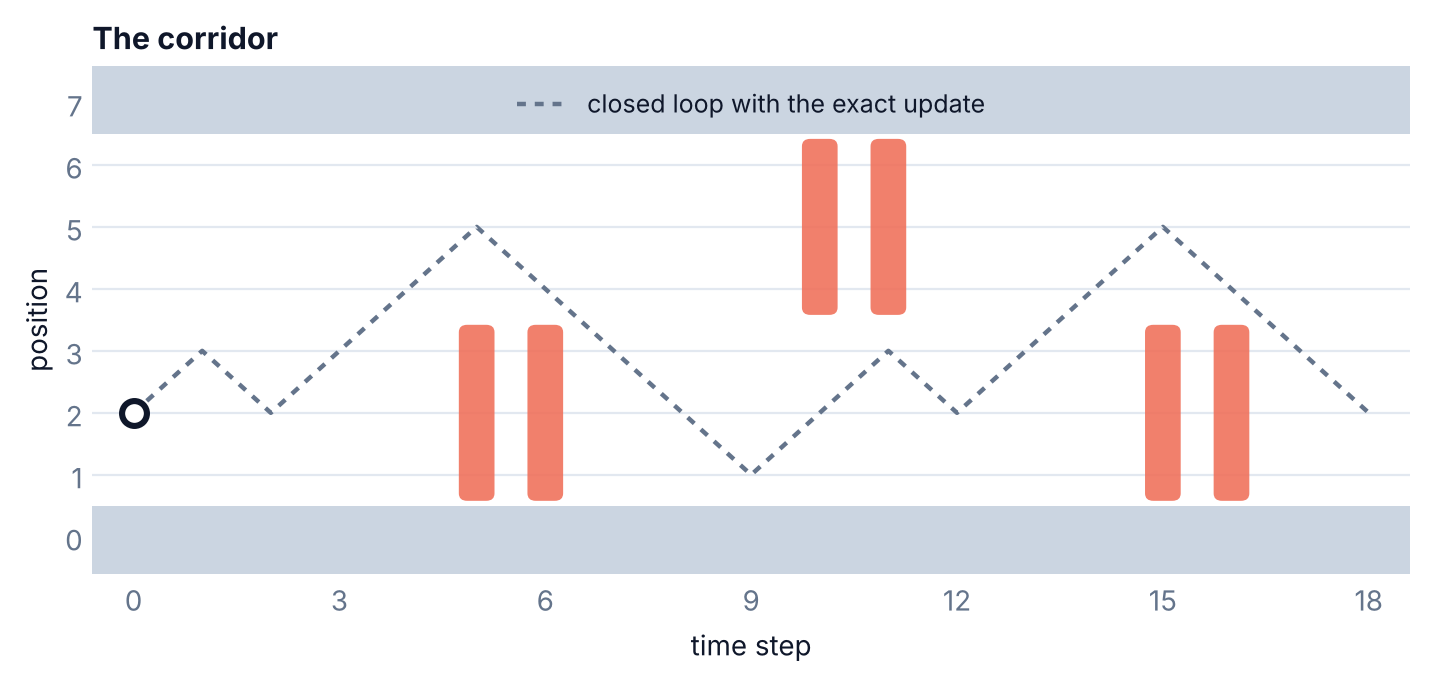

In [2]:
task = CorridorTask()

fig, ax = plt.subplots(figsize=(8.5, 3.3))
P.draw_corridor(ax, task)
ax.plot(exact_closed_loop(task), color=P.MUTED, ls=(0, (2, 2)), lw=1.6, label="closed loop with the exact update")
ax.scatter([0], [task.x_start], s=80, color="white", edgecolors=P.INK, linewidths=2.2, zorder=7)
ax.legend(loc="upper center", fontsize=9)
ax.set_title("The corridor");

## 2. One planning problem

At every control step the controller plans $N=5$ moves ahead. A plan is a string of five bits, one per move
($1$ means $+1$, $0$ means $-1$). We call it a **codeword** and store it as an integer whose bit $t$ is the move at step $t$.
There are $2^5 = 32$ plans.

`PlanningProblem.rollout` is the classical model. It returns the positions, the cost, and whether the plan is **feasible**
(never on a wall or an obstacle).

In [3]:
problem = PlanningProblem(task, x=task.x_start, t=0)

for codeword in (0b11011, 0b00000):
    r = problem.rollout(codeword)
    print(f"codeword {codeword:05b}  moves {r.moves}  positions {r.positions}  cost {r.cost:.1f}  feasible {r.feasible}")

print(f"\nfeasible plans: {problem.n_feasible} of {problem.n_codewords}   (p = {problem.feasible_mass:.3f})")

codeword 11011  moves (1, 1, -1, 1, 1)  positions (3, 4, 3, 4, 5)  cost 4.5  feasible True
codeword 00000  moves (-1, -1, -1, -1, -1)  positions (1, 0, -1, -2, -3)  cost 7.5  feasible False

feasible plans: 5 of 32   (p = 0.156)


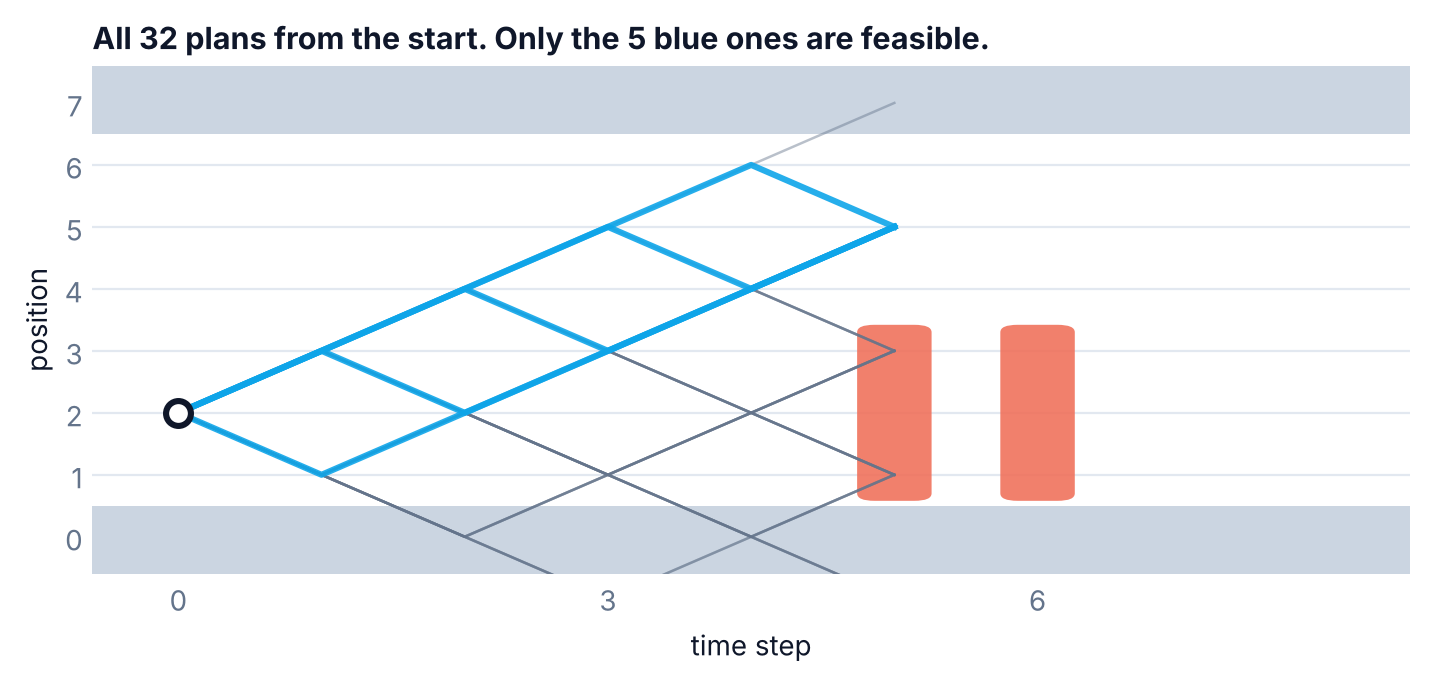

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 3.3))
P.draw_corridor(ax, task, t_max=8)
for z in range(problem.n_codewords):
    r = problem.rollout(z)
    ts, xs = P.path_xy(0, problem.x, r.positions)
    ax.plot(ts, xs, color=P.BLUE if r.feasible else P.MUTED, lw=2.2 if r.feasible else 0.9,
            alpha=0.9 if r.feasible else 0.45, zorder=4 if r.feasible else 3)
ax.scatter([0], [problem.x], s=80, color="white", edgecolors=P.INK, linewidths=2.2, zorder=7)
ax.set_title("All 32 plans from the start. Only the 5 blue ones are feasible.");

The obstacle at time 5 blocks the positions 1 to 3, so a feasible plan must be at position 5 after five moves.
Only 5 of the 32 plans do that. A classical sampler that draws plans at random wastes 27 of every 32 rollouts here.

## 3. The MPPI update

MPPI weights every feasible plan by $g = e^{-S/\lambda}$, where $S$ is its cost and $\lambda$ the temperature, and averages the first move $\epsilon_0 \in \{-1,+1\}$:

$$\nu \;=\; \frac{\sum_{z\ \text{feasible}} g(z)\,\epsilon_0(z)}{\sum_{z\ \text{feasible}} g(z)} .$$

With 32 plans we can compute $\nu$ exactly. A sampler estimates the same ratio from the plans it happens to draw.

In [5]:
nu = problem.exact_update()
print(f"exact update  nu = {nu:+.4f}   (positive: move up)\n")

print("classical sampling, 12 random plans per try")
for trial in range(5):
    codewords = rng.integers(0, problem.n_codewords, 12)
    update = mppi_update(problem, codewords)
    if update is None:
        print(f"  try {trial + 1}:  0 feasible of 12   no update at all")
    else:
        print(f"  try {trial + 1}: {update.n_accepted:2d} feasible of 12   nu_hat = {update.nu_hat:+.3f}")

exact update  nu = +0.2166   (positive: move up)

classical sampling, 12 random plans per try
  try 1:  2 feasible of 12   nu_hat = +1.000
  try 2:  2 feasible of 12   nu_hat = +1.000
  try 3:  4 feasible of 12   nu_hat = +1.000
  try 4:  1 feasible of 12   nu_hat = +1.000
  try 5:  1 feasible of 12   nu_hat = -1.000


With 12 rollouts the classical sampler keeps about two plans, sometimes none. That is the problem the circuit addresses.

## 4. The circuit

The circuit has three registers, 12 qubits in total.

| Register | Qubits | Content |
|---|---|---|
| `z` | 5 | the plan, one qubit per move |
| `y` | 2 | the position, stored as $\lfloor x/2 \rfloor$ (the lowest bit of $x$ is known from the time) |
| `f` | 5 | one flag per step, set to 1 if the position is unsafe at that time |

The **reversible rollout** below does on qubits what `problem.rollout` does on numbers. Each time step is a controlled
increment or decrement of the two-bit position counter (one Toffoli gate and one CNOT gate), followed by the gates that set the flag.

gates: {'x': 17, 'ccx': 10, 'cx': 5}


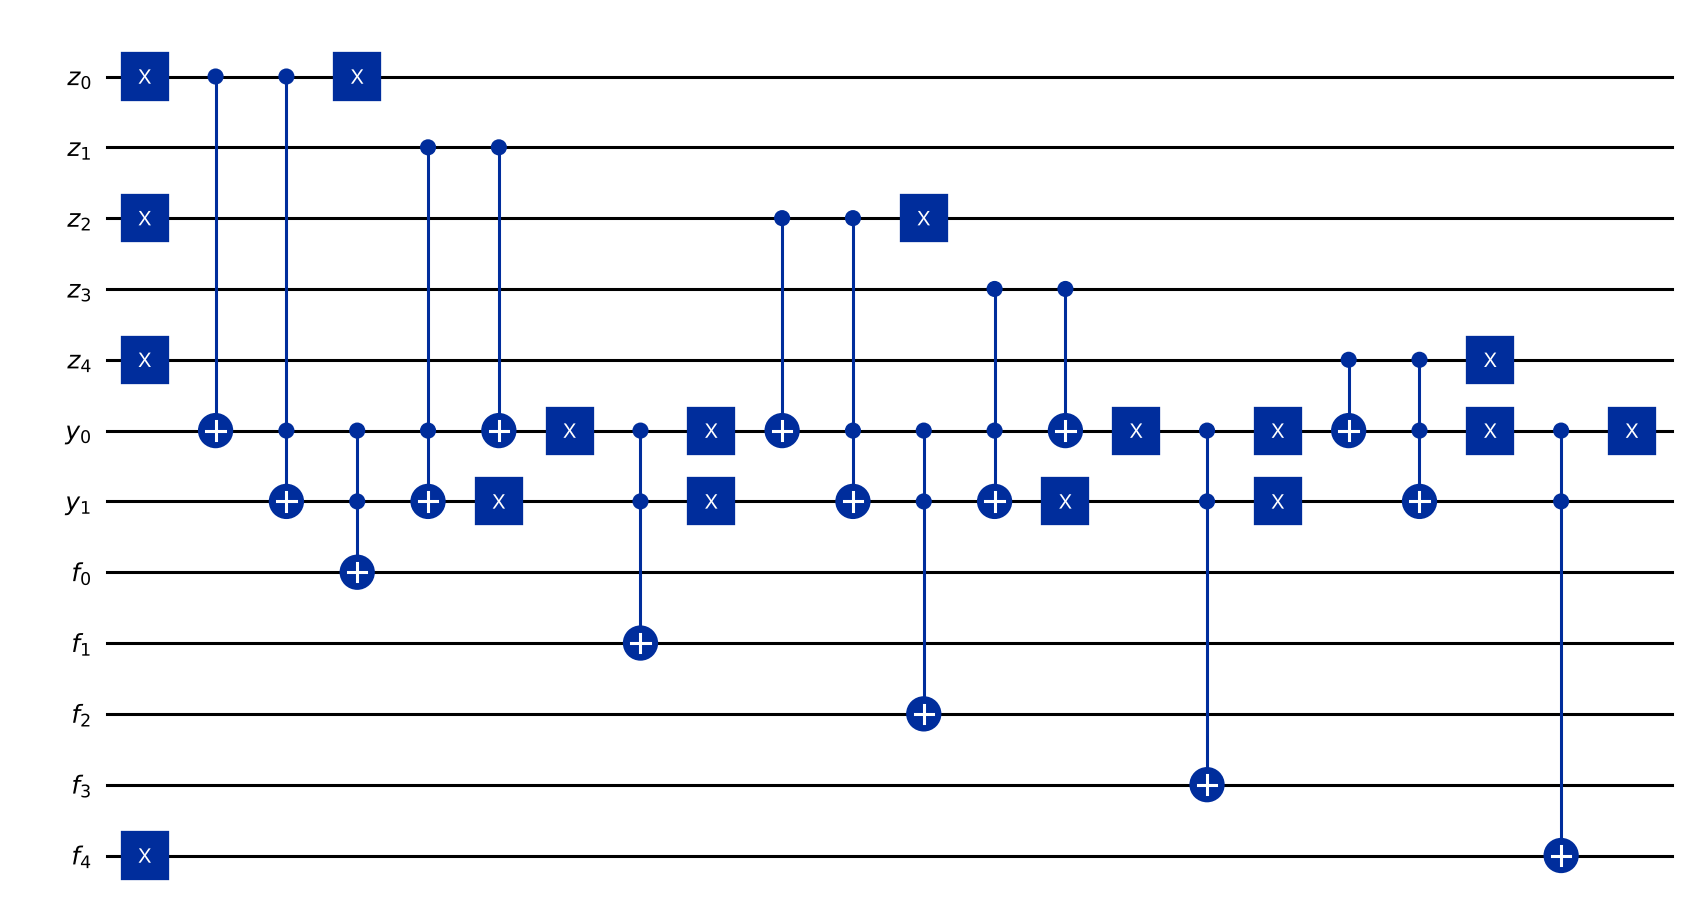

In [6]:
rollout = rollout_circuit(problem)
print("gates:", dict(rollout.count_ops()))
rollout.draw(output="mpl", fold=-1, scale=0.55);

**Check.** Feed one plan into the circuit and read the flags. They must agree with the classical rollout.

In [7]:
N = problem.N
for codeword in (0b11011, 0b00000):
    start = codeword | ((problem.x // 2) << N)           # plan in z, initial position in y, flags at zero
    state = Statevector.from_int(start, 2 ** rollout.num_qubits).evolve(rollout)
    index = int(np.argmax(np.abs(state.data)))
    flags = (index >> (N + 2)) & (2 ** N - 1)
    print(f"plan {codeword:05b}   flags f5..f1 = {flags:05b}   all zero: {flags == 0}   "
          f"classical rollout says feasible: {problem.rollout(codeword).feasible}")

plan 11011   flags f5..f1 = 00000   all zero: True   classical rollout says feasible: True
plan 00000   flags f5..f1 = 00110   all zero: False   classical rollout says feasible: False


## 5. Amplification

One shot of the sampler has three stages.

1. **Superpose.** Hadamard gates on `z` put all 32 plans into one state, each with amplitude $1/\sqrt{32}$.
2. **Mark.** Run the rollout, flip the sign of the state when all flags are zero, and undo the rollout. Feasible plans now have a negative amplitude.
3. **Reflect.** Reflect all amplitudes about their mean. The negative ones end up far above it.

Stages 2 and 3 together are one **Grover iteration**. The cell below reads the 32 amplitudes out of the simulator after each stage.

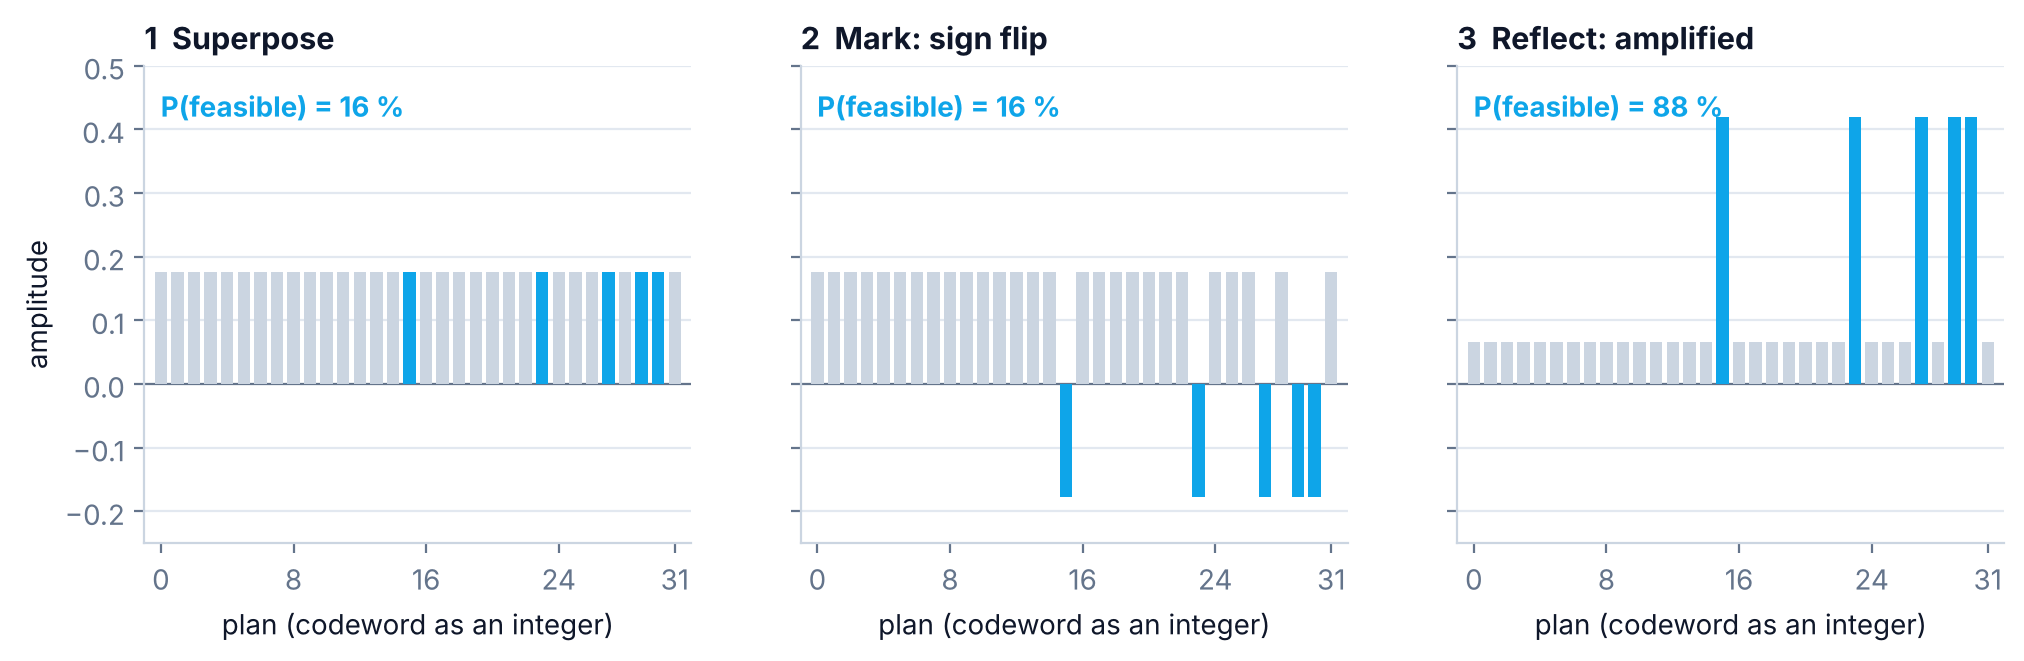

In [8]:
D = problem.n_codewords
feasible = problem.feasible_mask

def plan_amplitudes(circuit):
    data = Statevector(circuit).data.reshape(-1, D)[problem.x // 2]   # y and f are back in their initial state
    return np.real(data * np.sign(np.real(data).sum()))                # fix the global sign, which has no effect

stage_1 = preparation_circuit(problem)
stage_2 = stage_1.compose(oracle_circuit(problem))
stage_3 = stage_2.compose(reflection_circuit(problem))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.1), sharey=True)
titles = ["1  Superpose", "2  Mark: sign flip", "3  Reflect: amplified"]
for ax, circuit, title in zip(axes, (stage_1, stage_2, stage_3), titles):
    a = plan_amplitudes(circuit)
    P.bar_plans(ax, a, feasible, "amplitude" if ax is axes[0] else "", ylim=(-0.25, 0.5))
    ax.set_title(title)
    ax.text(0.03, 0.95, f"P(feasible) = {100 * (a[feasible] ** 2).sum():.0f} %", transform=ax.transAxes,
            ha="left", va="top", color=P.BLUE, fontweight="bold")

The probability of measuring a feasible plan went from 16 % to 88 % with one iteration.
In general, with $\sin^2\theta = p$, a measurement after $k$ iterations returns a feasible plan with probability

$$\alpha_k = \sin^2\big((2k+1)\,\theta\big),$$

and **every feasible plan is equally likely**. The circuit reproduces this to machine precision:

In [9]:
theta = np.arcsin(np.sqrt(problem.feasible_mass))
print("depth k   theory     circuit    rollouts per shot")
for k in range(4):
    probs = np.abs(Statevector(sampler_circuit(problem, k, measure=False)).data) ** 2
    on_z = probs.reshape(-1, D).sum(axis=0)
    print(f"   {k}      {np.sin((2 * k + 1) * theta) ** 2:.6f}   {on_z[feasible].sum():.6f}   {2 * k + 1}")

depth k   theory     circuit    rollouts per shot
   0      0.156250   0.156250   1
   1      0.881348   0.881348   3
   2      0.802040   0.802040   5
   3      0.085617   0.085617   7


More iterations are not always better. The probability oscillates, and every iteration costs two more rollouts
(one forward, one backward). For this problem one iteration is the best choice.

## 6. Measure and verify

`QuantumSampler` compiles the circuit to CNOT and single-qubit gates and runs it in Qiskit Aer. Each shot returns one plan.
The controller does **not** trust it. It rolls the plan out classically and keeps it only if it is feasible.

In [10]:
sampler = QuantumSampler(depth=1, seed=7)
shots = sampler.shots(problem, 8)

for z in shots:
    r = problem.rollout(int(z))
    print(f"shot {int(z):05b}   positions {r.positions}   {'verified' if r.feasible else 'REJECTED'}   cost {r.cost:.1f}")

shot 11011   positions (3, 4, 3, 4, 5)   verified   cost 4.5
shot 01111   positions (3, 4, 5, 6, 5)   verified   cost 6.5
shot 10111   positions (3, 4, 5, 4, 5)   verified   cost 5.5
shot 11011   positions (3, 4, 3, 4, 5)   verified   cost 4.5
shot 01111   positions (3, 4, 5, 6, 5)   verified   cost 6.5
shot 10111   positions (3, 4, 5, 4, 5)   verified   cost 5.5
shot 11110   positions (1, 2, 3, 4, 5)   verified   cost 3.5
shot 01001   positions (3, 2, 1, 2, 1)   REJECTED   cost 1.5


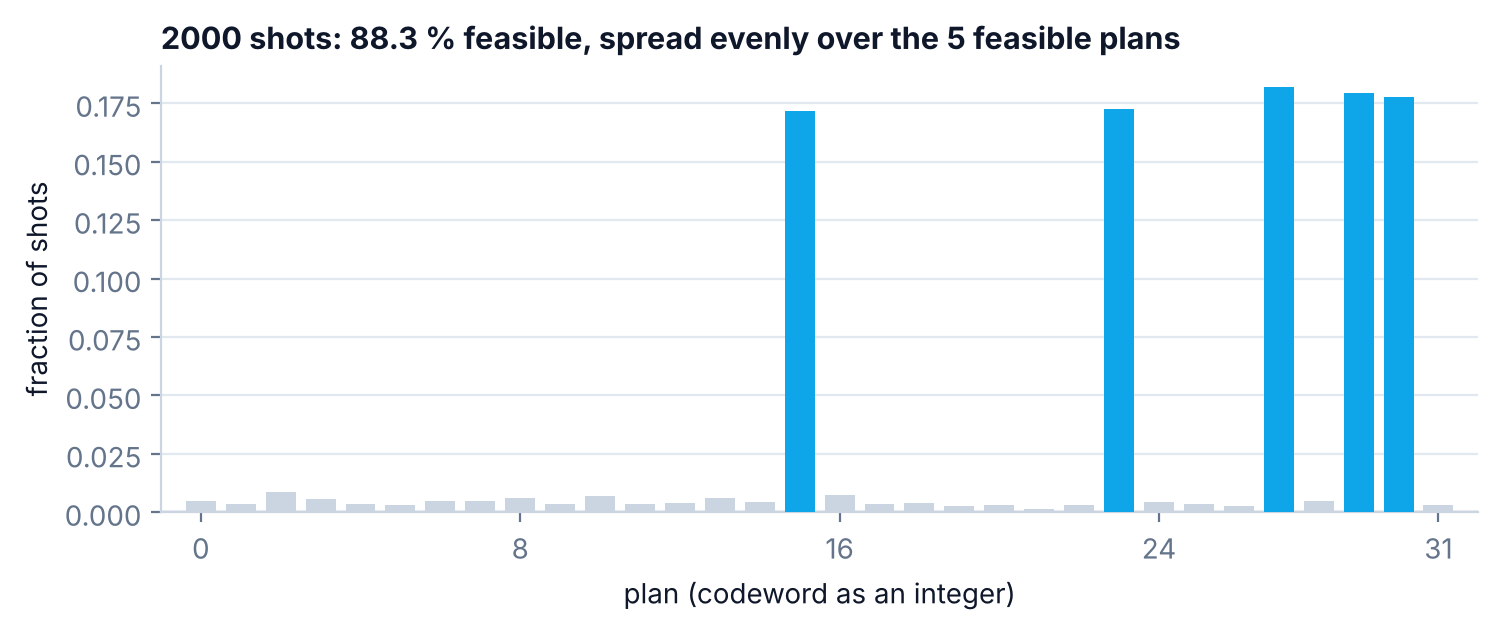

In [11]:
many = sampler.shots(problem, 2000)
counts = np.bincount(many, minlength=D)

fig, ax = plt.subplots(figsize=(8.5, 2.9))
P.bar_plans(ax, counts / 2000, feasible, "fraction of shots")
ax.set_title(f"2000 shots: {100 * counts[feasible].sum() / 2000:.1f} % feasible, spread evenly over the 5 feasible plans");

## 7. The MPPI update from verified shots

Nothing changes on the classical side. The verified plans go into the same weighted average.
At equal budget the comparison is 12 classical samples against 4 shots, because one shot at depth 1 costs 3 rollouts.

In [12]:
update = mppi_update(problem, shots)
print(f"8 shots: {update.n_accepted} verified, nu_hat = {update.nu_hat:+.3f}, exact nu = {nu:+.3f}, move {update.move:+d}\n")

budget, repeats = 12, 400
for name, s in (("classical", ClassicalSampler()), ("quantum, ideal", QuantumSampler(depth=1, seed=8))):
    empty, errors = 0, []
    for _ in range(repeats):
        codewords, used = s.propose(problem, budget, rng)
        u = mppi_update(problem, codewords)
        if u is None:
            empty += 1
        else:
            errors.append(abs(u.nu_hat - nu))
    print(f"{name:16s} budget {budget}: no feasible sample in {100 * empty / repeats:4.1f} % of the tries, "
          f"mean error {np.mean(errors):.3f}")

8 shots: 7 verified, nu_hat = +0.050, exact nu = +0.217, move +1

classical        budget 12: no feasible sample in 12.2 % of the tries, mean error 0.761


quantum, ideal   budget 12: no feasible sample in  0.0 % of the tries, mean error 0.595


## 8. Close the loop

`run_episode` repeats the steps above 18 times. At each step it executes the sign of $\hat\nu$ and keeps the cheapest
verified plan that starts with that move. If no shot is verified, it follows the rest of the stored plan.

In [13]:
episode = run_episode(task, QuantumSampler(depth=1, seed=5, batch=64), budget=24, rng=np.random.default_rng(5), verbose=True)
print("\nviolation:", episode["failed"], "  cost:", episode["cost"])

t= 0  x=2  p=0.156  proposed= 8  accepted= 6  nu_hat=+0.232  nu_exact=+0.217  move=+1  (sampled)
t= 1  x=3  p=0.250  proposed= 8  accepted= 8  nu_hat=-0.070  nu_exact=-0.288  move=-1  (sampled)
t= 2  x=2  p=0.094  proposed= 8  accepted= 5  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)
t= 3  x=3  p=0.188  proposed= 8  accepted= 7  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)
t= 4  x=4  p=0.312  proposed= 8  accepted= 8  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)


t= 5  x=5  p=0.156  proposed= 8  accepted= 7  nu_hat=-0.865  nu_exact=-0.961  move=-1  (sampled)
t= 6  x=4  p=0.250  proposed= 8  accepted= 8  nu_hat=-0.591  nu_exact=-0.892  move=-1  (sampled)
t= 7  x=3  p=0.281  proposed= 8  accepted= 8  nu_hat=-0.891  nu_exact=-0.689  move=-1  (sampled)


t= 8  x=2  p=0.375  proposed= 8  accepted= 7  nu_hat=+0.058  nu_exact=+0.000  move=+1  (sampled)


t= 9  x=3  p=0.312  proposed= 8  accepted= 8  nu_hat=-1.000  nu_exact=-1.000  move=-1  (sampled)
t=10  x=2  p=0.156  proposed= 8  accepted= 6  nu_hat=-0.689  nu_exact=+0.217  move=-1  (sampled)
t=11  x=1  p=0.062  proposed= 8  accepted= 5  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)
t=12  x=2  p=0.094  proposed= 8  accepted= 5  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)
t=13  x=3  p=0.188  proposed= 8  accepted= 8  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)


t=14  x=4  p=0.312  proposed= 8  accepted= 8  nu_hat=+1.000  nu_exact=+1.000  move=+1  (sampled)
t=15  x=5  p=0.594  proposed= 8  accepted= 1  nu_hat=-1.000  nu_exact=-0.950  move=-1  (sampled)
t=16  x=4  p=0.719  proposed= 8  accepted= 0  nu_hat=  n/a   nu_exact=-0.872  move=-1  (stored plan)


t=17  x=3  p=0.719  proposed= 8  accepted= 0  nu_hat=  n/a   nu_exact=-0.641  move=-1  (stored plan)

violation: False   cost: 10.5


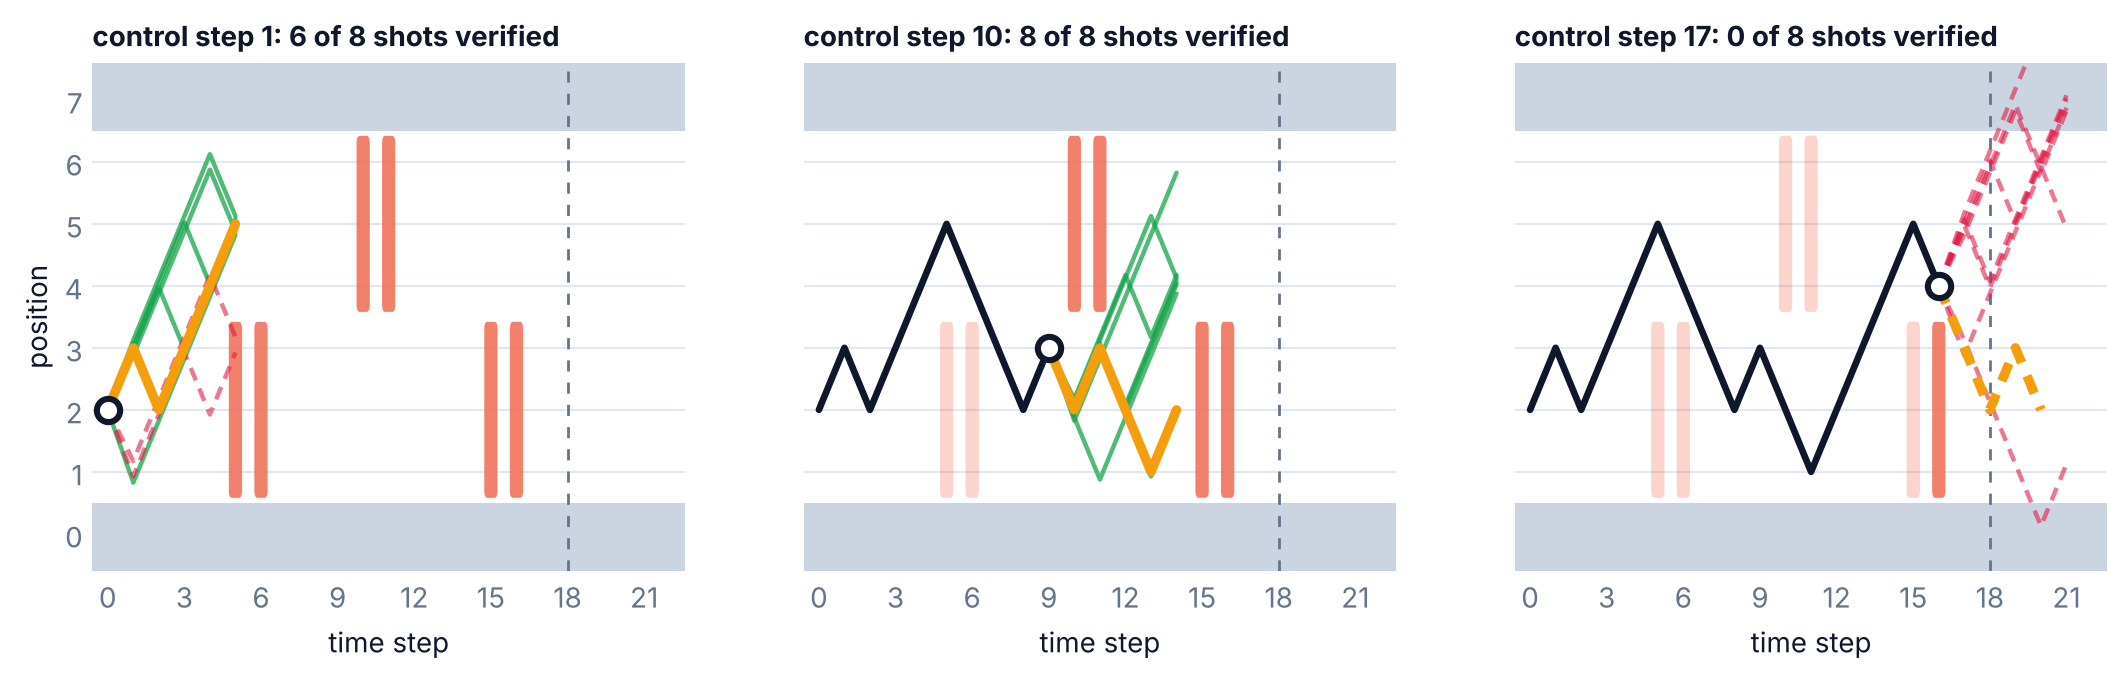

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for ax, k in zip(axes, (0, 9, 16)):
    step = episode["steps"][k]
    P.draw_corridor(ax, task, t_max=22, now=step["t"])
    P.draw_step(ax, step)
    P.draw_executed(ax, episode["trajectory"], upto=step["t"])
    ax.set_title(f"control step {step['t'] + 1}: {step['accepted']} of {step['proposed']} shots verified", fontsize=10)
    if ax is not axes[0]:
        ax.set_ylabel("")

Green: verified shots. Red dashed: rejected shots. Gold: the plan the controller keeps. Black: the path executed so far.

**The last panel is a limitation, shown on purpose.** Near the end of the episode most plans are feasible ($p \approx 0.7$).
One Grover iteration then rotates the state *past* the feasible plans, almost no shot passes, and the controller falls back
on its stored verified plan (gold, dashed). The adaptive sampler in `qmppi/samplers.py` avoids this by trying a few classical samples first.

## 9. A noisy device

Real devices make errors. Here every compiled gate is followed by depolarizing noise and every measured bit can flip.
The circuit has 160 CNOT gates, so at a gate error of 0.001 roughly one shot in six contains a fault.

In [15]:
print("device          accepted   counts on the 5 feasible plans")
for eta in (0.0, 1e-3, 5e-3):
    s = QuantumSampler(depth=1, eta=eta, seed=1)
    out = s.shots(problem, 1000)
    c = np.bincount(out, minlength=D)[feasible]
    print(f"{'ideal' if eta == 0 else 'gate error %g' % eta:15s} {c.sum() / 1000:.3f}      {[int(v) for v in c]}")
print(f"\nclassical sampling accepts {problem.feasible_mass:.3f} and costs 1 rollout; a shot costs 3")

device          accepted   counts on the 5 feasible plans
ideal           0.870      [183, 185, 169, 173, 160]


gate error 0.001 0.758      [143, 158, 157, 164, 136]


gate error 0.005 0.449      [88, 92, 93, 87, 89]

classical sampling accepts 0.156 and costs 1 rollout; a shot costs 3


Noise lowers the fraction of shots that pass the check. It does **not** let an infeasible plan through, because the check is classical,
and the verified shots stay spread evenly over the feasible plans. So noise costs budget, not correctness.
The break-even is where the acceptance falls to three times the classical one ($3p = 0.47$ here), which happens near a gate error of 0.005.
`examples/05_noise_study.py` maps this out.

## 10. The benchmark

`examples/04_benchmark.py` runs 300 episodes per entry and counts the episodes in which a constraint is violated.
Every sampler gets the same number of rollout evaluations per control step. The cell below only reads the stored result.

In [16]:
bench = json.load(open("results/benchmark.json"))
print(f"episodes with a violation, in percent ({bench['episodes']} episodes per entry)\n")
print(f"{'rollouts per control step':28s}" + "".join(f"{b:7d}" for b in bench["budgets"]))
for name, rows in bench["samplers"].items():
    print(f"{name:28s}" + "".join(f"{100 * r:7.1f}" for r in rows["failed"]))

episodes with a violation, in percent (300 episodes per entry)

rollouts per control step         6      9     12     18     24
classical sampling             12.3    4.3    3.3    0.3    0.0
quantum, ideal device           0.0    0.0    0.0    0.0    0.0
quantum, gate error 0.001       0.3    0.0    0.0    0.0    0.0
quantum, gate error 0.005       7.0    2.0    0.7    0.3    0.0
adaptive, ideal device          1.3    0.0    0.0    0.0    0.0
adaptive, gate error 0.001      3.3    0.0    0.0    0.0    0.0


The amplified sampler helps when the budget is tight, because fewer control steps end without any verified sample.
With a generous budget all samplers behave the same.

## What this notebook does not show

* **No hardware.** Everything is a simulation.
* **No speed-up in time.** Cost is counted in rollout evaluations. A reversible rollout on a quantum device costs far more elementary operations than a classical rollout.
* **No hard instance.** With 32 plans the exact update is one line (`problem.exact_update()`). The task is a test bed for the mechanism, not a case where a quantum device is needed.

**Where to go next:** `docs/how_it_works.md` for the reasoning behind each step, `examples/` for the scripts that produced `results/`, and `video/` for the animated version.